# KhabarNazar — Roman Urdu Fake News Detection, Run 2 (XLM-RoBERTa)

**Baseline (Colab run, `02_train_xlmr.ipynb`):** test macro-F1 0.833 overall, but Bend the Truth 0.662 and FIRE 0.722, against 0.878 on Hook and Bait. Headlines are ~80% of the training data, so the model mostly learns headline patterns.

**This run uses exactly the same train/val/test split** (`split_ids.csv` from `01_make_splits.ipynb`: stratified by source + label, near-duplicate articles kept in one split), so its test scores are directly comparable with the Colab run and the TF-IDF baseline.

**Changes compared with the Colab run**
1. **Oversampling of long-article sources in training** — Bend the Truth ×3, FIRE ×2 (train split only; val/test untouched).
2. **Head + tail truncation** — articles longer than 512 tokens keep their first 382 and last 128 tokens instead of only the beginning.
3. **Model selection by average per-source F1 on validation**, so the headline sources can't dominate which epoch is kept.
4. Up to 8 epochs with early stopping (patience 3).

Outputs go to `outputs/xlmr_roman_urdu_v2` and `models/xlmr_roman_urdu_v2_best`.

## 0. Download settings (must run first)

In [3]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

## 1. Environment & GPU check

In [4]:
import sys, platform
import torch, transformers, datasets, sklearn
print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__, "| CUDA avail.:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0), "| bf16:", torch.cuda.is_bf16_supported())
print("transformers:", transformers.__version__, "| datasets:", datasets.__version__, "| sklearn:", sklearn.__version__)

Python      : 3.12.4
PyTorch     : 2.11.0+cu128 | CUDA avail.: True
GPU         : NVIDIA RTX A4000 | bf16: True
transformers: 5.20.2 | datasets: 5.1.0 | sklearn: 1.9.1


## 2. Configuration

In [5]:
from pathlib import Path

# ---- Data ----
DATA_PATH   = Path(r"E:\KhabarNazar_text\data\khabarnazar_roman_urdu_dataset.csv")
TEXT_COL    = "roman_text"
LABEL_COL   = "label"
SOURCE_COL  = "source_dataset"
SPLIT_IDS_PATH = Path(r"E:\KhabarNazar_text\data\split_ids.csv")   # from 01_make_splits.ipynb
LABEL2ID    = {"Real": 0, "Fake": 1}

# Oversampling factors for the TRAIN split only (1 = no oversampling)
OVERSAMPLE  = {"bend_the_truth": 3, "fire": 2, "ax_to_grind": 1, "hook_and_bait": 1}

# ---- Model / training ----
MODEL_NAME   = "xlm-roberta-base"
MAX_LEN      = 512
TAIL_TOKENS  = 128      # for long articles: keep the last 128 tokens, the rest comes from the beginning
BATCH_SIZE   = 16
GRAD_ACCUM   = 2
LR           = 2e-5
EPOCHS       = 8
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
PATIENCE     = 3
USE_CLASS_WEIGHTS = True
SEED         = 42

# ---- Output (separate from run 1) ----
OUTPUT_DIR = Path("outputs/xlmr_roman_urdu_v2")
MODEL_DIR  = Path("models/xlmr_roman_urdu_v2_best")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

NUM_WORKERS = 0 if platform.system() == "Windows" else 2

import random, numpy as np, pandas as pd
from transformers import set_seed
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
print("Data file exists:", DATA_PATH.exists(), "| split file exists:", SPLIT_IDS_PATH.exists())

# Colab run (02_train_xlmr.ipynb) and TF-IDF baseline on the same test split, macro-F1 (outputs/results_table.csv)
COLAB_RESULTS = pd.DataFrame({
    "source":      ["ALL", "ax_to_grind", "bend_the_truth", "fire", "hook_and_bait"],
    "tfidf_lr_f1": [0.8204, 0.7934, 0.6577, 0.6234, 0.8952],
    "colab_xlmr_f1": [0.8329, 0.8381, 0.6619, 0.7216, 0.8783],
})

Data file exists: True | split file exists: True


## 3. Load and clean

In [ ]:
import pandas as pd

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df = df[["id", TEXT_COL, LABEL_COL, SOURCE_COL]].rename(
    columns={TEXT_COL: "text", LABEL_COL: "label_raw", SOURCE_COL: "source"})
n0 = len(df)
df = df.dropna(subset=["text", "label_raw", "source"])
df["text"] = df["text"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
df = df[df["text"].str.len() > 0]
df["label_raw"] = df["label_raw"].astype(str).str.strip().str.capitalize()
ID2LABEL = {i: lab for lab, i in LABEL2ID.items()}
df["label"] = df["label_raw"].map(LABEL2ID)
assert df["label"].notna().all(), "Some labels did not map; check LABEL2ID"
df["label"] = df["label"].astype(int)

print(f"Rows: {n0} -> {len(df)}")
pd.crosstab(df["source"], df["label_raw"], margins=True)

## 4. Use the fixed split from `01_make_splits.ipynb` (same as the Colab run)

In [7]:
split_ids = pd.read_csv(SPLIT_IDS_PATH)
df = df.merge(split_ids, on="id", how="left", validate="one_to_one")
assert df["split"].notna().all(), "Some articles have no split; is split_ids.csv the right file?"

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df   = df[df["split"] == "val"].reset_index(drop=True)
test_df  = df[df["split"] == "test"].reset_index(drop=True)
print("train / val / test:", len(train_df), len(val_df), len(test_df), "(Colab run: 6615 / 826 / 826)")

assert not set(train_df.text) & set(test_df.text)
assert not set(train_df.text) & set(val_df.text)
assert not set(val_df.text) & set(test_df.text)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    pass   # article text is not saved to outputs (the source datasets are not ours to redistribute)

pd.DataFrame({n: d["source"].value_counts() for n, d in
              [("train", train_df), ("val", val_df), ("test", test_df)]})

train / val / test: 6615 826 826 (Colab run: 6615 / 826 / 826)


,train,val,test
source,,,
hook_and_bait,3360,420,420
ax_to_grind,1980,248,247
bend_the_truth,717,88,89
fire,558,70,70


## 5. Oversample long-article sources (train only)

In [8]:
parts = []
for src, g in train_df.groupby("source"):
    parts.append(pd.concat([g] * OVERSAMPLE.get(src, 1)))
train_os = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"Train rows: {len(train_df)} -> {len(train_os)} after oversampling")
pd.DataFrame({"original": train_df["source"].value_counts(),
              "oversampled": train_os["source"].value_counts()})

Train rows: 6615 -> 8607 after oversampling


,original,oversampled
source,,
ax_to_grind,1980,1980
bend_the_truth,717,2151
fire,558,1116
hook_and_bait,3360,3360


## 6. Tokenize with head + tail truncation

Articles that fit in 512 tokens are unchanged. Longer ones keep the first `MAX_LEN - 2 - TAIL_TOKENS` tokens and the last `TAIL_TOKENS` tokens.

In [9]:
from transformers import AutoTokenizer
from datasets import Dataset, DatasetDict

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
BODY = MAX_LEN - 2                 # room left after <s> and </s>
HEAD = BODY - TAIL_TOKENS

def encode_head_tail(texts):
    enc = tokenizer(texts, add_special_tokens=False, truncation=False)["input_ids"]
    input_ids, attention = [], []
    for ids in enc:
        if len(ids) > BODY:
            ids = ids[:HEAD] + ids[-TAIL_TOKENS:]
        ids = [tokenizer.cls_token_id] + ids + [tokenizer.sep_token_id]
        input_ids.append(ids)
        attention.append([1] * len(ids))
    return {"input_ids": input_ids, "attention_mask": attention}

def to_ds(d):
    return Dataset.from_pandas(d[["text", "label"]].reset_index(drop=True))

raw = DatasetDict(train=to_ds(train_os), validation=to_ds(val_df), test=to_ds(test_df))
tokenized = raw.map(lambda b: encode_head_tail(b["text"]), batched=True, remove_columns=["text"])

lens = [len(x) for x in tokenized["train"]["input_ids"]]
print("Max length after head+tail:", max(lens))
assert max(lens) <= MAX_LEN
tokenized

Map:   0%|          | 0/8607 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (855 > 512). Running this sequence through the model will result in indexing errors


Map:   0%|          | 0/826 [00:00<?, ? examples/s]

Map:   0%|          | 0/826 [00:00<?, ? examples/s]

Max length after head+tail: 512


DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 8607
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 826
    })
    test: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 826
    })
})

## 7. Model, metrics (incl. per-source F1) and class-weighted loss

In [10]:
import torch.nn as nn
from transformers import (AutoModelForSequenceClassification, DataCollatorWithPadding,
                          TrainingArguments, Trainer, EarlyStoppingCallback)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID)
collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Evaluation runs over the validation set in order, so we can line up each prediction with its source
VAL_SOURCES = val_df["source"].to_numpy()
SOURCES = sorted(df["source"].unique())

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    out = {"accuracy": accuracy_score(labels, preds), "precision_macro": p,
           "recall_macro": r, "f1_macro": f}
    if len(labels) == len(VAL_SOURCES):          # only on the validation set
        per = []
        for s in SOURCES:
            m = VAL_SOURCES == s
            fs = f1_score(labels[m], preds[m], average="macro", zero_division=0)
            out[f"f1_{s}"] = fs
            per.append(fs)
        out["f1_source_avg"] = float(np.mean(per))
    return out

counts = np.bincount(train_os["label"], minlength=2)
class_weights = torch.tensor(len(train_os) / (2 * counts), dtype=torch.float)
print("Train class counts:", counts, "| class weights:", class_weights.numpy().round(3))

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

TrainerClass = WeightedTrainer if USE_CLASS_WEIGHTS else Trainer

W1021 18:59:13.213000 18032 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | Details
----------------------------+------------+--------
roberta.pooler.dense.bias   | UNEXPECTED |        
roberta.pooler.dense.weight | UNEXPECTED |        
lm_head.layer_norm.weight   | UNEXPECTED |        
lm_head.layer_norm.bias     | UNEXPECTED |        
lm_head.bias                | UNEXPECTED |        
lm_head.dense.weight        | UNEXPECTED |        
lm_head.dense.bias          | UNEXPECTED |        
classifier.dense.weight     | MISSING    |        
classifier.out_proj.bias    | MISSING    |        
classifier.dense.bias       | MISSING    |        
classifier.out_proj.weight  | MISSING    |        

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Train class counts: [4581 4026] | class weights: [0.939 1.069]


## 8. Training arguments

In [11]:
import math
use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
use_fp16 = torch.cuda.is_available() and not use_bf16
steps_per_epoch = math.ceil(len(tokenized["train"]) / (BATCH_SIZE * GRAD_ACCUM))
WARMUP_STEPS = int(WARMUP_RATIO * steps_per_epoch * EPOCHS)

args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "checkpoints"),
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=WARMUP_STEPS,
    lr_scheduler_type="linear",
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    save_only_model=True,          # skip the 2+ GB optimizer state in each checkpoint (saves disk space)
    load_best_model_at_end=True,
    metric_for_best_model="f1_source_avg",
    greater_is_better=True,
    logging_steps=25,
    bf16=use_bf16,
    fp16=use_fp16,
    dataloader_num_workers=NUM_WORKERS,
    report_to="none",
    seed=SEED,
)
print("Steps/epoch:", steps_per_epoch, "| warmup steps:", WARMUP_STEPS,
      "| mixed precision:", "bf16" if use_bf16 else "fp16" if use_fp16 else "off")

trainer = TrainerClass(
    model=model, args=args,
    train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
    processing_class=tokenizer, data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)

Steps/epoch: 269 | warmup steps: 215 | mixed precision: bf16


## 9. Train

In [12]:
import time
t0 = time.time()
train_result = trainer.train()
print(f"\nTraining time: {(time.time()-t0)/60:.1f} min")
print("Best checkpoint:", trainer.state.best_model_checkpoint, "| best f1_source_avg:", trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Ax To Grind,F1 Bend The Truth,F1 Fire,F1 Hook And Bait,F1 Source Avg
1,1.141725,0.530856,0.745763,0.755431,0.749037,0.744751,0.785506,0.598069,0.728682,0.749633,0.715472
2,0.803681,0.413953,0.820823,0.821779,0.819618,0.820110,0.826542,0.573112,0.783282,0.861855,0.761198
3,0.661350,0.414043,0.835351,0.835481,0.834693,0.834964,0.842719,0.674654,0.768977,0.864112,0.787616
4,0.481989,0.583070,0.819613,0.836369,0.815456,0.815789,0.786306,0.607143,0.724482,0.875909,0.748460
5,0.334736,0.559931,0.834140,0.835347,0.835286,0.834140,0.842719,0.692825,0.761905,0.868719,0.791542
6,0.209574,0.711759,0.840194,0.840919,0.839190,0.839652,0.822164,0.709571,0.781827,0.880942,0.798626
7,0.209641,0.922706,0.828087,0.831549,0.826099,0.826844,0.830104,0.616800,0.761905,0.869041,0.769462
8,0.088452,0.913971,0.837772,0.838482,0.836766,0.837223,0.834546,0.664488,0.748262,0.880928,0.782056


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training time: 24.3 min
Best checkpoint: outputs\xlmr_roman_urdu_v2\checkpoints\checkpoint-1614 | best f1_source_avg: 0.798625928881038


## 10. Training curves

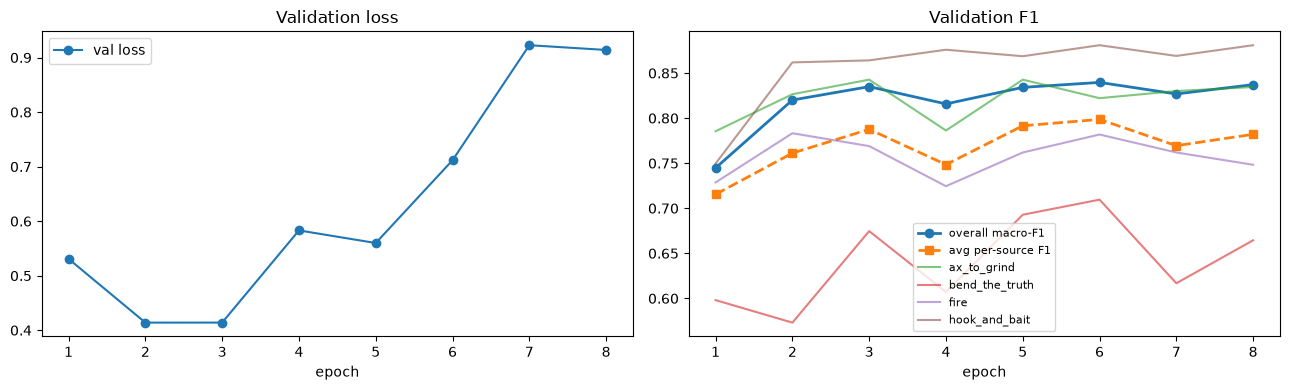

,epoch,eval_loss,eval_f1_macro,eval_f1_source_avg,eval_f1_ax_to_grind,eval_f1_bend_the_truth,eval_f1_fire,eval_f1_hook_and_bait
10,1.0,0.5309,0.7448,0.7155,0.7855,0.5981,0.7287,0.7496
22,2.0,0.4140,0.8201,0.7612,0.8265,0.5731,0.7833,0.8619
34,3.0,0.4140,0.8350,0.7876,0.8427,0.6747,0.7690,0.8641
46,4.0,0.5831,0.8158,0.7485,0.7863,0.6071,0.7245,0.8759
57,5.0,0.5599,0.8341,0.7915,0.8427,0.6928,0.7619,0.8687
69,6.0,0.7118,0.8397,0.7986,0.8222,0.7096,0.7818,0.8809
81,7.0,0.9227,0.8268,0.7695,0.8301,0.6168,0.7619,0.8690
93,8.0,0.9140,0.8372,0.7821,0.8345,0.6645,0.7483,0.8809


In [13]:
import matplotlib.pyplot as plt
hist = pd.DataFrame(trainer.state.log_history)
hist.to_csv(OUTPUT_DIR / "log_history.csv", index=False)
ev = hist.dropna(subset=["eval_loss"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ev.epoch, ev.eval_loss, "o-", label="val loss")
ax[0].set_xlabel("epoch"); ax[0].set_title("Validation loss"); ax[0].legend()
ax[1].plot(ev.epoch, ev.eval_f1_macro, "o-", label="overall macro-F1", linewidth=2)
ax[1].plot(ev.epoch, ev.eval_f1_source_avg, "s--", label="avg per-source F1", linewidth=2)
for s in SOURCES:
    ax[1].plot(ev.epoch, ev[f"eval_f1_{s}"], alpha=.6, label=s)
ax[1].set_xlabel("epoch"); ax[1].set_title("Validation F1"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150); plt.show()

ev[["epoch", "eval_loss", "eval_f1_macro", "eval_f1_source_avg"] + [f"eval_f1_{s}" for s in SOURCES]].round(4)

## 11. Test set: overall results

              precision    recall  f1-score   support

        Real     0.8253    0.8407    0.8329       427
        Fake     0.8261    0.8095    0.8177       399

    accuracy                         0.8257       826
   macro avg     0.8257    0.8251    0.8253       826
weighted avg     0.8257    0.8257    0.8256       826



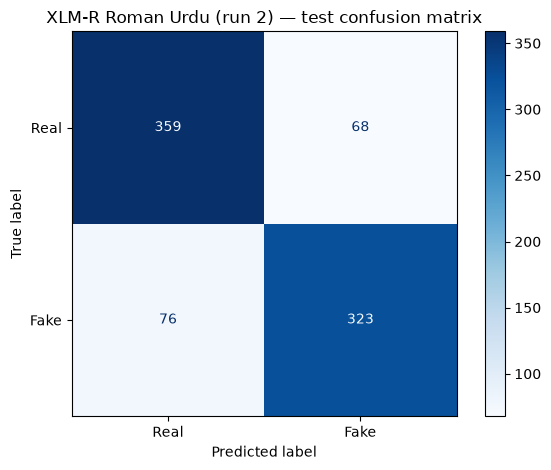

In [14]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pred_out = trainer.predict(tokenized["test"])
test_preds = pred_out.predictions.argmax(-1)
test_labels = pred_out.label_ids
target_names = [ID2LABEL[i] for i in range(2)]

report = classification_report(test_labels, test_preds, target_names=target_names, digits=4)
print(report)
(OUTPUT_DIR / "test_classification_report.txt").write_text(report)

cm = confusion_matrix(test_labels, test_preds)
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(cmap="Blues", values_format="d")
plt.title("XLM-R Roman Urdu (run 2) — test confusion matrix")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=150); plt.show()

## 12. Test set: per source, compared with the Colab run and the TF-IDF baseline

In [15]:
t = test_df.reset_index(drop=True).copy()   # same order as tokenized["test"]
t["pred"] = test_preds
rows = [{"source": "ALL", "n": len(t),
         "accuracy": round(accuracy_score(t["label"], t["pred"]), 3),
         "f1_macro": round(f1_score(t["label"], t["pred"], average="macro"), 3),
         "errors": int((t["label"] != t["pred"]).sum())}]
for s, g in t.groupby("source"):
    rows.append({"source": s, "n": len(g),
                 "accuracy": round(accuracy_score(g["label"], g["pred"]), 3),
                 "f1_macro": round(f1_score(g["label"], g["pred"], average="macro"), 3),
                 "errors": int((g["label"] != g["pred"]).sum())})
per_source = pd.DataFrame(rows)
per_source.to_csv(OUTPUT_DIR / "test_per_source.csv", index=False)
cmp = COLAB_RESULTS.merge(per_source[["source", "n", "f1_macro"]].rename(columns={"f1_macro": "gpu_run2_f1"}), on="source")
cmp["change_vs_colab"] = (cmp["gpu_run2_f1"] - cmp["colab_xlmr_f1"]).round(3)
cmp = cmp[["source", "n", "tfidf_lr_f1", "colab_xlmr_f1", "gpu_run2_f1", "change_vs_colab"]]
cmp.to_csv(OUTPUT_DIR / "results_table_run2.csv", index=False)
print("Macro-F1 on the same test split (single runs, seed 42; small sources have wide error margins):")
display(cmp)

Macro-F1 on the same test split (single runs, seed 42; small sources have wide error margins):


,source,n,tfidf_lr_f1,colab_xlmr_f1,gpu_run2_f1,change_vs_colab
0,ALL,826,0.8204,0.8329,0.825,-0.008
1,ax_to_grind,247,0.7934,0.8381,0.797,-0.041
2,bend_the_truth,89,0.6577,0.6619,0.652,-0.010
3,fire,70,0.6234,0.7216,0.728,0.006
4,hook_and_bait,420,0.8952,0.8783,0.890,0.012


## 13. Error analysis

In [ ]:
probs = torch.softmax(torch.tensor(pred_out.predictions).float(), dim=-1).numpy()
t["pred_label"] = [ID2LABEL[i] for i in test_preds]
t["confidence"] = probs.max(axis=1).round(3)
errors = t[t["pred"] != t["label"]].sort_values("confidence", ascending=False)
# ids only in the saved file (no article text); the table below shows the text locally
errors[["id", "source", "label_raw", "pred_label", "confidence"]].to_csv(OUTPUT_DIR / "test_errors_ids.csv", index=False)
print(f"{len(errors)} misclassified out of {len(t)}")
print(errors["source"].value_counts())
pd.set_option("display.max_colwidth", 200)
errors[["source", "text", "label_raw", "pred_label", "confidence"]].head(15)

## 14. Save the model

In [17]:
import json
trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))
with open(MODEL_DIR / "training_config.json", "w") as f:
    json.dump({"run": 2, "model_name": MODEL_NAME, "max_len": MAX_LEN, "truncation": "head+tail",
               "tail_tokens": TAIL_TOKENS, "oversample": OVERSAMPLE, "batch_size": BATCH_SIZE,
               "grad_accum": GRAD_ACCUM, "lr": LR, "epochs_max": EPOCHS, "seed": SEED,
               "selection_metric": "f1_source_avg", "label2id": LABEL2ID, "split": "split_ids.csv (01_make_splits.ipynb)",
               "test_metrics": {k: v for k, v in pred_out.metrics.items() if isinstance(v, (int, float))},
               "test_per_source": per_source.to_dict(orient="records")}, f, indent=2)
print("Saved to", MODEL_DIR.resolve())

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to E:\KhabarNazar_text\models\xlmr_roman_urdu_v2_best


## 15. Inference with the saved model

Uses the same head+tail encoding as training. Paste real articles into `tests` to try it.

In [ ]:
inf_tok = AutoTokenizer.from_pretrained(str(MODEL_DIR))
inf_model = AutoModelForSequenceClassification.from_pretrained(str(MODEL_DIR)).eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
inf_model.to(device)

def predict(texts):
    enc = encode_head_tail(list(texts))
    batch = inf_tok.pad(enc, return_tensors="pt").to(device)
    with torch.no_grad():
        p = torch.softmax(inf_model(**batch).logits.float(), dim=-1).cpu().numpy()
    return [(inf_model.config.id2label[int(i)], round(float(row[i]), 3)) for row, i in zip(p, p.argmax(1))]

tests = test_df.sample(4, random_state=1)
for (lab, conf), (_, r) in zip(predict(tests["text"]), tests.iterrows()):
    print(f"pred={lab:4s} ({conf}) | true={r.label_raw:4s} | {r.source:14s} | {r.text[:90]}")